In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Project directories
ROOT = Path.cwd().resolve().parent

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
TABLES_DIR = ROOT / "outputs" / "tables"

# Confirm project structure
print("Project root:", ROOT)
print("Raw data directory exists:", RAW_DIR.is_dir())

print("\nAvailable source files:")
for file in sorted(RAW_DIR.glob("*.csv")):
    print("-", file.name)

Project root: C:\Users\tsholofelom\Documents\Research Projects\ghs-2025-healthcare-inequality
Raw data directory exists: True

Available source files:
- ghs-2025-household-v1.csv
- ghs-2025-person-v1.csv


In [2]:
# This formats floats to show up to 2 decimal places without scientific notation
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [3]:
# ============================================================
# LOAD SOURCE DATASETS
# ============================================================

household_raw = pd.read_csv(
    RAW_DIR / "ghs-2025-household-v1.csv",
    encoding="cp1252",
    dtype=str,
    low_memory=False
)

person_raw = pd.read_csv(
    RAW_DIR / "ghs-2025-person-v1.csv",
    encoding="cp1252",
    dtype=str,
    low_memory=False
)

print("HOUSEHOLD DATASET")
print("Rows:", len(household_raw))
print("Columns:", household_raw.shape[1])

print("\nPERSON DATASET")
print("Rows:", len(person_raw))
print("Columns:", person_raw.shape[1])

print("\nDatasets loaded successfully.")

HOUSEHOLD DATASET
Rows: 20095
Columns: 207

PERSON DATASET
Rows: 67748
Columns: 124

Datasets loaded successfully.


In [4]:
# ============================================================
# IDENTIFIER AND LINKAGE VALIDATION
# ============================================================

# Check required identifiers
assert {"uqnr"}.issubset(household_raw.columns)
assert {"uqnr", "personnr"}.issubset(person_raw.columns)

# Household identifier checks
print("HOUSEHOLD IDENTIFIERS")
print("Missing household IDs:", household_raw["uqnr"].isna().sum())
print("Duplicate household IDs:", household_raw["uqnr"].duplicated().sum())

# Person identifier checks
print("\nPERSON IDENTIFIERS")
print("Missing household IDs:", person_raw["uqnr"].isna().sum())
print("Missing person numbers:", person_raw["personnr"].isna().sum())

print(
    "Duplicate household-person combinations:",
    person_raw.duplicated(subset=["uqnr", "personnr"]).sum()
)

# Check household-person linkage
unmatched = ~person_raw["uqnr"].isin(household_raw["uqnr"])

print("\nHOUSEHOLD-PERSON LINKAGE")
print("Persons without matching households:", unmatched.sum())

# Validate data integrity
assert household_raw["uqnr"].notna().all()
assert household_raw["uqnr"].is_unique
assert person_raw[["uqnr", "personnr"]].notna().all().all()
assert not person_raw.duplicated(subset=["uqnr", "personnr"]).any()
assert not unmatched.any()

print("\nIdentifier and linkage validation passed.")

HOUSEHOLD IDENTIFIERS
Missing household IDs: 0
Duplicate household IDs: 0

PERSON IDENTIFIERS
Missing household IDs: 0
Missing person numbers: 0
Duplicate household-person combinations: 0

HOUSEHOLD-PERSON LINKAGE
Persons without matching households: 0

Identifier and linkage validation passed.


In [5]:
# ============================================================
# SURVEY-DESIGN VALIDATION
# ============================================================

design_vars = ["house_wgt", "psu", "stratum"]

# Confirm required variables exist
assert set(design_vars).issubset(household_raw.columns)

# Convert household weights to numeric
household_weights = pd.to_numeric(
    household_raw["house_wgt"],
    errors="coerce"
)

print("SURVEY-DESIGN VALIDATION")
print("-" * 50)

print("Missing household weights:", household_weights.isna().sum())
print("Non-positive household weights:", household_weights.le(0).sum())

print("\nMissing PSU values:", household_raw["psu"].isna().sum())
print("Missing stratum values:", household_raw["stratum"].isna().sum())

print("\nUnique PSUs:", household_raw["psu"].nunique())
print("Unique strata:", household_raw["stratum"].nunique())

# Count PSUs within each stratum
psus_per_stratum = (
    household_raw.groupby("stratum")["psu"].nunique()
)

print(
    "Strata containing only one PSU:",
    psus_per_stratum.eq(1).sum()
)

# Validate essential design information
assert household_weights.notna().all()
assert household_weights.gt(0).all()
assert household_raw[["psu", "stratum"]].notna().all().all()

print("\nSurvey-design validation passed.")

SURVEY-DESIGN VALIDATION
--------------------------------------------------
Missing household weights: 0
Non-positive household weights: 0

Missing PSU values: 0
Missing stratum values: 0

Unique PSUs: 3226
Unique strata: 248
Strata containing only one PSU: 0

Survey-design validation passed.


In [6]:
# ============================================================
# INITIALISE WORKING DATASETS
# ============================================================

# Preserve original datasets
household = household_raw.copy()
person = person_raw.copy()

# Convert household survey weights to numeric
household["house_wgt"] = pd.to_numeric(
    household["house_wgt"],
    errors="coerce"
)

# Confirm dimensions are unchanged
assert len(household) == len(household_raw)
assert len(person) == len(person_raw)

print("Working datasets initialised successfully.")
print("Households:", len(household))
print("Persons:", len(person))
print("Household weights numeric:", pd.api.types.is_numeric_dtype(household["house_wgt"]))

Working datasets initialised successfully.
Households: 20095
Persons: 67748
Household weights numeric: True


In [7]:
# ============================================================
# INSPECT HEALTHCARE TRAVEL-TIME CATEGORIES
# ============================================================

print("HHW_TIME RESPONSE CATEGORIES")
print("-" * 50)

print(
    household["hhw_time"].value_counts(
        dropna=False
    )
)

print("\nTotal households:", len(household))

HHW_TIME RESPONSE CATEGORIES
--------------------------------------------------
hhw_time
15â€“29 minutes         9180
Less than 15 minutes    7707
30â€“89 minutes         2948
90 minutes and more      236
DO NOT KNOW               22
Unspecified                2
Name: count, dtype: int64

Total households: 20095


In [8]:
# ============================================================
# CONSTRUCT TRAVEL-TIME OUTCOME
# ============================================================

# Extract the numeric lower bound from each time category
travel_time = household["hhw_time"].str.extract(
    r"^(\d+)"
)[0]

# Handle the category beginning with "Less than"
travel_time = travel_time.mask(
    household["hhw_time"].eq("Less than 15 minutes"),
    "0"
)

# Construct binary indicator
household["travel30_hh"] = (
    pd.to_numeric(travel_time, errors="coerce")
    .ge(30)
    .astype("Int64")
)

# Preserve unknown and unspecified responses as missing
household.loc[
    travel_time.isna(),
    "travel30_hh"
] = pd.NA

# Validate
print("TRAVEL-TIME OUTCOME")
print("-" * 50)

print(household["travel30_hh"].value_counts(dropna=False))

assert household["travel30_hh"].notna().sum() == household[
    "hhw_time"
].isin([
    "Less than 15 minutes",
    "15â€“29 minutes",
    "30â€“89 minutes",
    "90 minutes and more"
]).sum()

print("\nTravel-time outcome constructed successfully.")

TRAVEL-TIME OUTCOME
--------------------------------------------------
travel30_hh
0       16887
1        3184
<NA>       24
Name: count, dtype: Int64

Travel-time outcome constructed successfully.


In [9]:
# ============================================================
# INSPECT HEALTHCARE FACILITY CATEGORIES
# ============================================================

print("HEALTHCARE FACILITY CATEGORIES")
print("-" * 50)

print(
    household["hhw_hltfac"].value_counts(
        dropna=False
    )
)

print("\nTotal households:", len(household))

HEALTHCARE FACILITY CATEGORIES
--------------------------------------------------
hhw_hltfac
2. Public sector: Clinic                                        14182
6. Private sector: Private doctor/specialist                     3444
1. Public sector: Hospital                                       1311
4. Private sector: Hospital                                       392
5. Private sector: Clinic                                         321
9. Private sector: Pharmacy/chemist                               268
3. Public sector: Other in the public sector                       44
7. Private sector: Traditional healer                              36
10. Private sector: Health facility provided by employer           36
8. Private sector: Spiritual healer's workplace/church             27
12. Private sector: Other in private sector                        13
11. Private sector: Alternative medicine, e.g. homoeopathist       10
13. Private sector: DO NOT KNOW                                    

In [10]:
# ============================================================
# CONSTRUCT PUBLIC-SECTOR RELIANCE OUTCOME
# ============================================================

facility = household["hhw_hltfac"]

# Identify valid public and private facility responses
is_public = facility.str.contains(
    "Public sector:",
    case=False,
    na=False
)

is_private = (
    facility.str.contains(
        "Private sector:",
        case=False,
        na=False
    )
    & ~facility.str.contains(
        "DO NOT KNOW|Unspecified",
        case=False,
        na=False
    )
)

# Construct binary outcome
household["public_sector_hh"] = pd.Series(
    pd.NA,
    index=household.index,
    dtype="Int64"
)

household.loc[is_public, "public_sector_hh"] = 1
household.loc[is_private, "public_sector_hh"] = 0

# Validate
print("PUBLIC-SECTOR RELIANCE OUTCOME")
print("-" * 50)

print(
    household["public_sector_hh"].value_counts(
        dropna=False
    )
)

assert (
    household["public_sector_hh"].notna().sum()
    == (is_public | is_private).sum()
)

assert len(household) == len(household_raw)

print("\nPublic-sector reliance outcome constructed successfully.")

PUBLIC-SECTOR RELIANCE OUTCOME
--------------------------------------------------
public_sector_hh
1       15537
0        4547
<NA>       11
Name: count, dtype: Int64

Public-sector reliance outcome constructed successfully.


In [11]:
# ============================================================
# INSPECT GEOGRAPHIC VARIABLES
# ============================================================

geo_vars = ["prov", "geotype", "metro"]

for var in geo_vars:
    print(f"\n{var.upper()}")
    print("-" * 50)

    if var in household.columns:
        print(household[var].value_counts(dropna=False))
    else:
        print("Variable not found")


PROV
--------------------------------------------------
prov
7. Gauteng          5316
5. KwaZulu-Natal    3160
2. Eastern Cape     2638
9. Limpopo          2244
1. Western Cape     1807
8. Mpumalanga       1568
6. North West       1311
4. Free State       1193
3. Northern Cape     858
Name: count, dtype: int64

GEOTYPE
--------------------------------------------------
geotype
1    13027
2     6347
3      721
Name: count, dtype: int64

METRO
--------------------------------------------------
metro
2. Non-metro    12124
1. Metro         7971
Name: count, dtype: int64


In [12]:
# ============================================================
# PREPARE GEOGRAPHIC VARIABLES
# ============================================================

# Remove numeric prefixes from province labels
household["province_hh"] = household["prov"].str.replace(
    r"^\d+\.\s*", "", regex=True
)

# Remove numeric prefixes from metro labels
household["metro_hh"] = household["metro"].str.replace(
    r"^\d+\.\s*", "", regex=True
)

# Preserve geotype codes until official labels are verified
household["geotype_hh"] = household["geotype"].copy()

# Validate against original variables
assert household["province_hh"].notna().sum() == household["prov"].notna().sum()
assert household["metro_hh"].notna().sum() == household["metro"].notna().sum()
assert household["geotype_hh"].equals(household["geotype"])

print("GEOGRAPHIC VARIABLES PREPARED")
print("-" * 50)

for var in ["province_hh", "metro_hh", "geotype_hh"]:
    print(f"\n{var}")
    print(household[var].value_counts(dropna=False))

print("\nGeographic variables prepared successfully.")

GEOGRAPHIC VARIABLES PREPARED
--------------------------------------------------

province_hh
province_hh
Gauteng          5316
KwaZulu-Natal    3160
Eastern Cape     2638
Limpopo          2244
Western Cape     1807
Mpumalanga       1568
North West       1311
Free State       1193
Northern Cape     858
Name: count, dtype: int64

metro_hh
metro_hh
Non-metro    12124
Metro         7971
Name: count, dtype: int64

geotype_hh
geotype_hh
1    13027
2     6347
3      721
Name: count, dtype: int64

Geographic variables prepared successfully.


In [13]:
# ============================================================
# INSPECT MONTHLY HOUSEHOLD INCOME
# ============================================================

income = household["totmhinc"]

print("MONTHLY HOUSEHOLD INCOME")
print("-" * 50)

print("Missing source values:", income.isna().sum())

print("\nMost frequent responses:")
print(income.value_counts(dropna=False).head(15))

print("\nNon-numeric or special response categories:")
print(
    income[
        ~income.str.match(r"^\d+\.", na=False)
    ].value_counts(dropna=False)
)

print("\nResponses containing 'Unspecified':")
print(
    income[
        income.str.contains("Unspecified", case=False, na=False)
    ].value_counts()
)

MONTHLY HOUSEHOLD INCOME
--------------------------------------------------
Missing source values: 0

Most frequent responses:
totmhinc
1990. 1990              817
9999999. Unspecified    432
350. 350                347
2010. 2010              271
21583. 21583            270
4000. 4000              255
0. 0                    240
5257. 5257              228
5000. 5000              227
3980. 3980              216
6958. 6958              209
2000. 2000              204
2470. 2470              179
6000. 6000              176
9475. 9475              168
Name: count, dtype: int64

Non-numeric or special response categories:
Series([], Name: count, dtype: int64)

Responses containing 'Unspecified':
totmhinc
9999999. Unspecified    432
Name: count, dtype: int64


In [14]:
# ============================================================
# CLEAN MONTHLY HOUSEHOLD INCOME
# ============================================================

# Extract numeric income from labelled responses
household["income_monthly_hh"] = pd.to_numeric(
    household["totmhinc"].str.extract(r"^(\d+)\.")[0],
    errors="coerce"
)

# Identify unspecified responses from their labels
unspecified = household["totmhinc"].str.contains(
    "Unspecified",
    case=False,
    na=False
)

household.loc[unspecified, "income_monthly_hh"] = np.nan

# Validate
print("MONTHLY HOUSEHOLD INCOME")
print("-" * 50)

print("Valid incomes:", household["income_monthly_hh"].notna().sum())
print("Missing incomes:", household["income_monthly_hh"].isna().sum())
print("Zero incomes:", household["income_monthly_hh"].eq(0).sum())

print("\nIncome summary (unweighted):")
print(
    household["income_monthly_hh"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

assert household["income_monthly_hh"].isna().sum() == unspecified.sum()
assert household["income_monthly_hh"].dropna().ge(0).all()

print("\nMonthly household income cleaned successfully.")

MONTHLY HOUSEHOLD INCOME
--------------------------------------------------
Valid incomes: 19663
Missing incomes: 432
Zero incomes: 240

Income summary (unweighted):
count     19663.00
mean      11899.36
std       25768.15
min           0.00
25%        2470.00
50%        5257.00
75%       12000.00
95%       44000.00
99%      100000.00
max     1070000.00
Name: income_monthly_hh, dtype: float64

Monthly household income cleaned successfully.


In [15]:
# ============================================================
# HOUSEHOLD SIZE AND PER-CAPITA INCOME
# ============================================================

# Convert household size to numeric
household["household_size_hh"] = pd.to_numeric(
    household["hholdsz"].str.extract(r"^(\d+)")[0],
    errors="coerce"
)

# Count linked persons per household
person_counts = person.groupby("uqnr").size()

# Match counts to household records
linked_counts = household["uqnr"].map(person_counts)

# Validate household size
print("HOUSEHOLD SIZE VALIDATION")
print("-" * 50)

print("Missing household sizes:",
      household["household_size_hh"].isna().sum())

print("Non-positive household sizes:",
      household["household_size_hh"].le(0).sum())

print("Mismatch with linked person records:",
      household["household_size_hh"].ne(linked_counts).sum())

assert household["household_size_hh"].notna().all()
assert household["household_size_hh"].gt(0).all()
assert household["household_size_hh"].eq(linked_counts).all()

# Calculate per-capita monthly household income
household["income_pc_hh"] = (
    household["income_monthly_hh"]
    / household["household_size_hh"]
)

print("\nPER-CAPITA MONTHLY HOUSEHOLD INCOME")
print("-" * 50)

print("Valid:", household["income_pc_hh"].notna().sum())
print("Missing:", household["income_pc_hh"].isna().sum())

print("\nSummary (unweighted):")
print(
    household["income_pc_hh"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("\nHousehold size and per-capita income validated.")

HOUSEHOLD SIZE VALIDATION
--------------------------------------------------
Missing household sizes: 0
Non-positive household sizes: 0
Mismatch with linked person records: 0

PER-CAPITA MONTHLY HOUSEHOLD INCOME
--------------------------------------------------
Valid: 19663
Missing: 432

Summary (unweighted):
count    19663.00
mean      4561.75
std       9919.62
min          0.00
25%        896.90
50%       1990.00
75%       4500.00
95%      18000.00
99%      40000.00
max     535000.00
Name: income_pc_hh, dtype: float64

Household size and per-capita income validated.


In [16]:
# ============================================================
# INSPECT FOOD-INSECURITY VARIABLES
# ============================================================

food_vars = [
    "fsd_worried",
    "fsd_healthy",
    "fsd_fewfoods",
    "fsd_skipped",
    "fsd_ateless",
    "fsd_ranout",
    "fsd_hungry",
    "fsd_whlday"
]

# Confirm all required variables exist
assert set(food_vars).issubset(household.columns)

# Inspect response categories
for var in food_vars:
    print(f"\n{var.upper()}")
    print(household[var].value_counts(dropna=False))


FSD_WORRIED
fsd_worried
2. No             15164
1. Yes             4906
9. Unspecified       25
Name: count, dtype: int64

FSD_HEALTHY
fsd_healthy
2. No             15219
1. Yes             4852
9. Unspecified       24
Name: count, dtype: int64

FSD_FEWFOODS
fsd_fewfoods
2. No             15191
1. Yes             4887
9. Unspecified       17
Name: count, dtype: int64

FSD_SKIPPED
fsd_skipped
2. No             16610
1. Yes             3455
9. Unspecified       30
Name: count, dtype: int64

FSD_ATELESS
fsd_ateless
2. No             16077
1. Yes             3992
9. Unspecified       26
Name: count, dtype: int64

FSD_RANOUT
fsd_ranout
2. No             16457
1. Yes             3617
9. Unspecified       21
Name: count, dtype: int64

FSD_HUNGRY
fsd_hungry
2. No             17348
1. Yes             2723
9. Unspecified       24
Name: count, dtype: int64

FSD_WHLDAY
fsd_whlday
2. No             18064
1. Yes             2017
9. Unspecified       14
Name: count, dtype: int64


In [17]:
# ============================================================
# CONSTRUCT FOOD-INSECURITY INDICATOR
# ============================================================

# Recode the eight food-insecurity items
food_items = household[food_vars].replace({
    "1. Yes": 1,
    "2. No": 0,
    "9. Unspecified": np.nan
}).astype(float)

# Identify households with at least one Yes
any_yes = food_items.eq(1).any(axis=1)

# Identify households with eight confirmed No responses
all_no = food_items.eq(0).all(axis=1)

# Construct indicator: 1 = Any Yes, 0 = All No
household["food_insecure_any_hh"] = pd.Series(
    pd.NA,
    index=household.index,
    dtype="Int64"
)

household.loc[any_yes, "food_insecure_any_hh"] = 1
household.loc[all_no, "food_insecure_any_hh"] = 0

# Validate
print("FOOD-INSECURITY INDICATOR")
print("-" * 50)

print(
    household["food_insecure_any_hh"].value_counts(
        dropna=False
    )
)

assert (any_yes & all_no).sum() == 0
assert household["food_insecure_any_hh"].notna().sum() == (
    any_yes | all_no
).sum()

assert len(household) == len(household_raw)

print("\nFood-insecurity indicator constructed successfully.")

FOOD-INSECURITY INDICATOR
--------------------------------------------------
food_insecure_any_hh
0       13972
1        6035
<NA>       88
Name: count, dtype: Int64

Food-insecurity indicator constructed successfully.


In [18]:
# ============================================================
# INSPECT ENABLING-RESOURCE VARIABLES
# ============================================================

print("PERSON-LEVEL MEDICAL AID")
print("-" * 50)

print(
    person["hlt_medi"].value_counts(dropna=False)
)

print("\nHOUSEHOLD VEHICLE OWNERSHIP")
print("-" * 50)

print(
    household["hwl_vehicle"].value_counts(dropna=False)
)

print("\n TRANSPORTATION MODE")
print("-" * 50)

print(
    household["hhw_transp"].value_counts(dropna=False)
)

PERSON-LEVEL MEDICAL AID
--------------------------------------------------
hlt_medi
2. No             59081
1. Yes             8542
3. DO NOT KNOW      124
9. Unspecified        1
Name: count, dtype: int64

HOUSEHOLD VEHICLE OWNERSHIP
--------------------------------------------------
hwl_vehicle
2. No             14476
1. Yes             5615
9. Unspecified        4
Name: count, dtype: int64

 TRANSPORTATION MODE
--------------------------------------------------
hhw_transp
1. Walking                                         9811
2. Minibus taxi/sedan taxi/bakkie taxi             5585
5. Own transport                                   4254
7. Other means of transport to nearest facility     282
3. Bus                                              113
6. Bicycle/motorcycle                                38
4. Train                                             10
9. Unspecified                                        2
Name: count, dtype: int64


In [19]:
# ============================================================
# CONSTRUCT HOUSEHOLD MEDICAL AID INDICATOR
# ============================================================

# Recode person-level medical aid
person["medical_aid_person"] = person["hlt_medi"].map({
    "1. Yes": 1,
    "2. No": 0
})

# Aggregate medical aid responses by household
aid_summary = person.groupby("uqnr")["medical_aid_person"].agg(
    members="size",
    valid_responses="count",
    insured_members="sum"
)

# Determine household medical aid status
aid_summary["any_medical_aid_hh"] = pd.Series(
    pd.NA,
    index=aid_summary.index,
    dtype="Int64"
)

# At least one member has medical aid
aid_summary.loc[
    aid_summary["insured_members"] > 0,
    "any_medical_aid_hh"
] = 1

# All members have confirmed No responses
aid_summary.loc[
    (aid_summary["insured_members"] == 0) &
    (aid_summary["valid_responses"] == aid_summary["members"]),
    "any_medical_aid_hh"
] = 0

# Attach the indicator without merging unnecessary columns
household["any_medical_aid_hh"] = household["uqnr"].map(
    aid_summary["any_medical_aid_hh"]
).astype("Int64")

# Validate
print("HOUSEHOLD MEDICAL AID")
print("-" * 50)

print(
    household["any_medical_aid_hh"].value_counts(
        dropna=False
    )
)

assert len(household) == len(household_raw)
assert household["any_medical_aid_hh"].dropna().isin([0, 1]).all()

print("\nHousehold medical aid indicator constructed successfully.")

HOUSEHOLD MEDICAL AID
--------------------------------------------------
any_medical_aid_hh
0       16080
1        3931
<NA>       84
Name: count, dtype: Int64

Household medical aid indicator constructed successfully.


In [20]:
# ============================================================
# VEHICLE OWNERSHIP AND TRANSPORTATION MODE
# ============================================================

# Household vehicle ownership
household["vehicle_owner_hh"] = household["hwl_vehicle"].map({
    "1. Yes": 1,
    "2. No": 0
}).astype("Int64")

# Extract transportation mode codes
transport_code = household["hhw_transp"].str.extract(
    r"^(\d+)\."
)[0]

# Group transportation modes
transport_map = {
    "1": "Walking",
    "2": "Public/shared transport",
    "3": "Public/shared transport",
    "4": "Public/shared transport",
    "5": "Own transport",
    "6": "Own transport",
    "7": "Other"
}

household["health_transport_hh"] = transport_code.map(
    transport_map
)

# Validate
print("VEHICLE OWNERSHIP")
print("-" * 50)
print(household["vehicle_owner_hh"].value_counts(dropna=False))

print("\nHEALTHCARE TRANSPORTATION MODE")
print("-" * 50)
print(household["health_transport_hh"].value_counts(dropna=False))

assert household["vehicle_owner_hh"].dropna().isin([0, 1]).all()
assert len(household) == len(household_raw)

print("\nEnabling-resource variables constructed successfully.")

VEHICLE OWNERSHIP
--------------------------------------------------
vehicle_owner_hh
0       14476
1        5615
<NA>        4
Name: count, dtype: Int64

HEALTHCARE TRANSPORTATION MODE
--------------------------------------------------
health_transport_hh
Walking                    9811
Public/shared transport    5708
Own transport              4292
Other                       282
NaN                           2
Name: count, dtype: int64

Enabling-resource variables constructed successfully.


In [21]:
# ============================================================
# HOUSEHOLD DEMOGRAPHIC CHARACTERISTICS
# ============================================================

# Convert person age to numeric
person["age_num"] = pd.to_numeric(
    person["age"].str.extract(r"^(\d+)")[0],
    errors="coerce"
)

# Check age completeness and range
print("PERSON AGE VALIDATION")
print("-" * 50)
print("Missing ages:", person["age_num"].isna().sum())
print("Minimum age:", person["age_num"].min())
print("Maximum age:", person["age_num"].max())

# Identify children and older adults
person["child_under18"] = person["age_num"].lt(18)
person["older_adult60"] = person["age_num"].ge(60)

# Aggregate to household level
composition = person.groupby("uqnr").agg(
    children_under18_hh=("child_under18", "any"),
    older_adults60_hh=("older_adult60", "any")
)

# Attach indicators to household dataset
household["children_under18_hh"] = (
    household["uqnr"]
    .map(composition["children_under18_hh"])
    .astype("Int64")
)

household["older_adults60_hh"] = (
    household["uqnr"]
    .map(composition["older_adults60_hh"])
    .astype("Int64")
)

# Validate
print("\nHOUSEHOLD COMPOSITION")
print("-" * 50)

for var in ["children_under18_hh", "older_adults60_hh"]:
    print(f"\n{var}")
    print(household[var].value_counts(dropna=False))

assert person["age_num"].notna().all()
assert person["age_num"].between(0, 120).all()
assert household[
    ["children_under18_hh", "older_adults60_hh"]
].notna().all().all()

print("\nHousehold demographic indicators constructed successfully.")

PERSON AGE VALIDATION
--------------------------------------------------
Missing ages: 0
Minimum age: 0
Maximum age: 105

HOUSEHOLD COMPOSITION
--------------------------------------------------

children_under18_hh
children_under18_hh
1    10212
0     9883
Name: count, dtype: Int64

older_adults60_hh
older_adults60_hh
0    13715
1     6380
Name: count, dtype: Int64

Household demographic indicators constructed successfully.


In [22]:
# ============================================================
# INSPECT SEX AND PERSON-LEVEL SURVEY WEIGHTS
# ============================================================

print("SEX DISTRIBUTION")
print("-" * 50)

print(person["Sex"].value_counts(dropna=False))

print("\nAVAILABLE PERSON-LEVEL WEIGHT COLUMNS")
print("-" * 50)

weight_columns = [
    col for col in person.columns
    if "wgt" in col.lower()
    or "weight" in col.lower()
]

print(weight_columns)

for col in weight_columns:
    print(f"\n{col}")
    print(person[col].head())
    print("Missing:", person[col].isna().sum())

print("\nAGE COMPLETENESS BY SEX")
print("-" * 50)

print(
    person.groupby("Sex", dropna=False)["age_num"]
    .agg(["count", "min", "median", "max"])
)

SEX DISTRIBUTION
--------------------------------------------------
Sex
2. Female    35161
1. Male      32587
Name: count, dtype: int64

AVAILABLE PERSON-LEVEL WEIGHT COLUMNS
--------------------------------------------------
['person_wgt']

person_wgt
0    782.0718251660001
1        725.027502607
2         851.73692763
3         851.73692763
4        979.758375057
Name: person_wgt, dtype: str
Missing: 0

AGE COMPLETENESS BY SEX
--------------------------------------------------
           count  min  median  max
Sex                               
1. Male    32587    0   26.00  103
2. Female  35161    0   30.00  105


In [23]:
# ============================================================
# CLEAN SEX AND PERSON-LEVEL SURVEY WEIGHT
# ============================================================

# Recode sex
person["sex_person"] = person["Sex"].map({
    "1. Male": "Male",
    "2. Female": "Female"
})

# Convert survey weight to numeric
person["person_wgt"] = pd.to_numeric(
    person["person_wgt"],
    errors="coerce"
)

# Validate
print("SEX")
print("-" * 50)
print(person["sex_person"].value_counts(dropna=False))

print("\nPERSON-LEVEL SURVEY WEIGHT")
print("-" * 50)
print("Missing weights:", person["person_wgt"].isna().sum())
print("Non-positive weights:", (person["person_wgt"] <= 0).sum())
print("Minimum weight:", person["person_wgt"].min())
print("Maximum weight:", person["person_wgt"].max())

assert person["sex_person"].notna().all()
assert person["person_wgt"].notna().all()
assert (person["person_wgt"] > 0).all()
assert len(person) == len(person_raw)

print("\nSex and person-level survey weight validated successfully.")

SEX
--------------------------------------------------
sex_person
Female    35161
Male      32587
Name: count, dtype: int64

PERSON-LEVEL SURVEY WEIGHT
--------------------------------------------------
Missing weights: 0
Non-positive weights: 0
Minimum weight: 50.0
Maximum weight: 6194.95331135

Sex and person-level survey weight validated successfully.


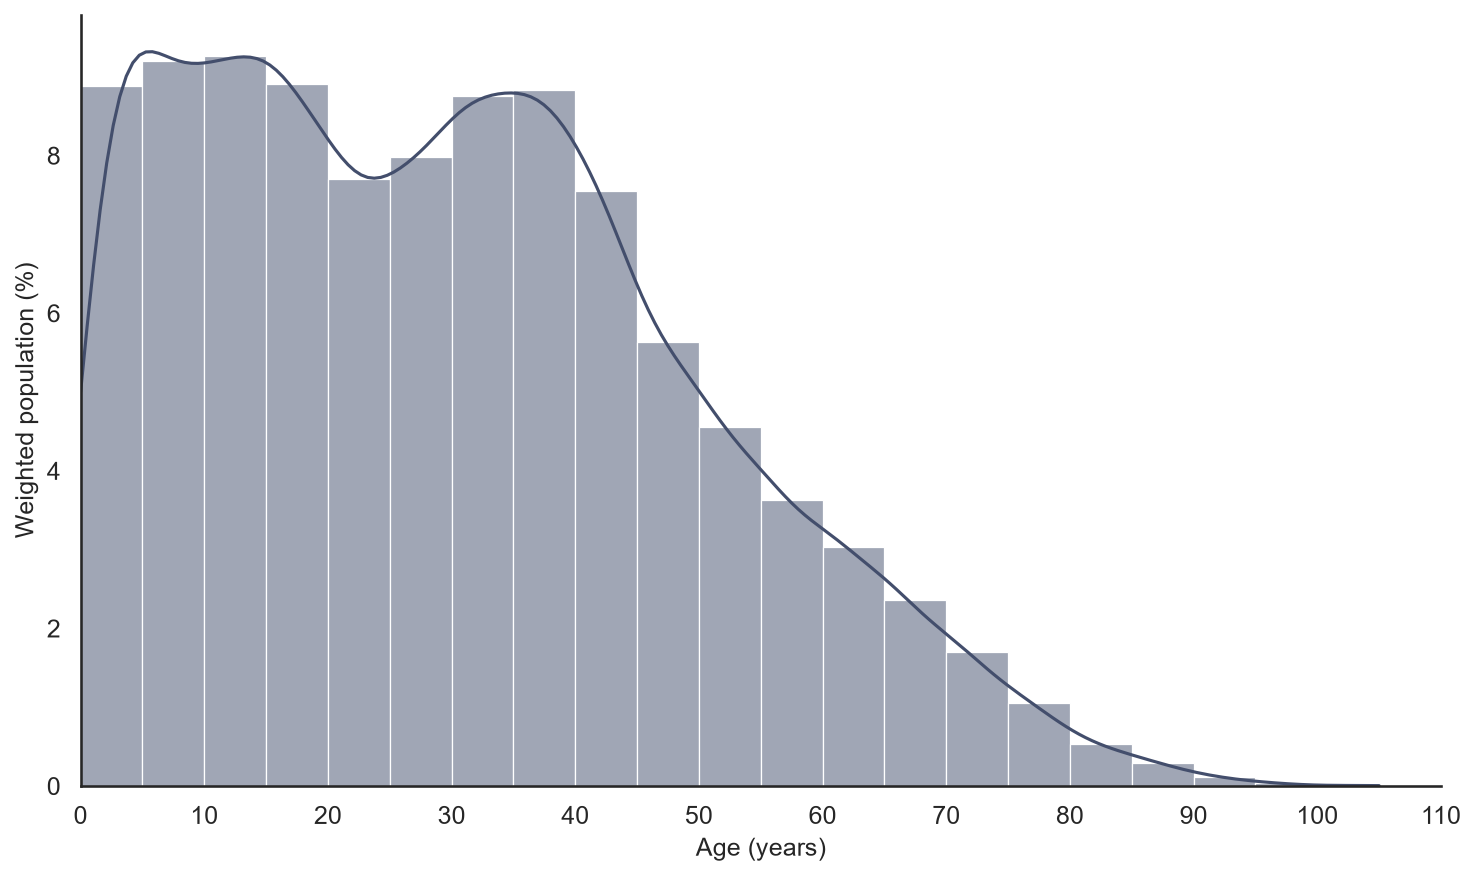

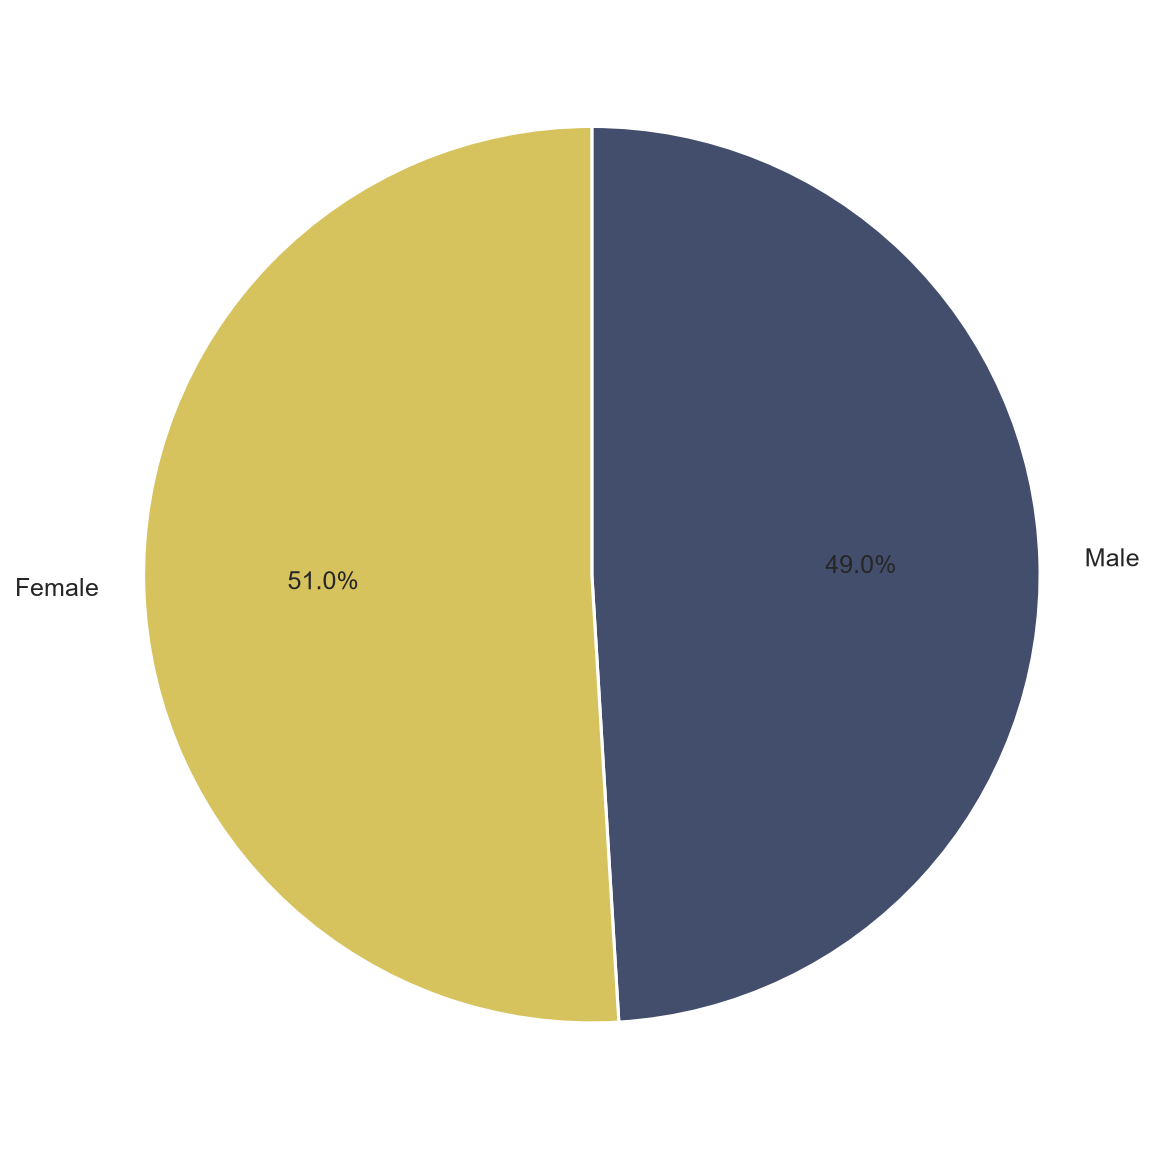

Both figures exported to: C:\Users\tsholofelom\Documents\Research Projects\ghs-2025-healthcare-inequality\outputs\figures


In [25]:
# ============================================================
# AGE AND SEX DISTRIBUTION FIGURES
# ============================================================


# Plotting configuration
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.titlesize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

sns.set_style("white")

export_png = True
export_pdf = True

out_dir = str(ROOT / "outputs" / "figures")
os.makedirs(out_dir, exist_ok=True)

def safe_name(s: str) -> str:
    return "".join(
        c if (c.isalnum() or c in "-_") else "_"
        for c in s
    ).strip("_")

colors = plt.cm.cividis(np.linspace(0.25, 0.85, 2))


# ============================================================
# FIGURE 1: SURVEY-WEIGHTED AGE DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=person,
    x="age_num",
    weights="person_wgt",
    bins=np.arange(0, 111, 5).tolist(),
    stat="percent",
    color=colors[0],
    edgecolor="white",
    linewidth=0.6,
    kde=True,
    ax=ax
)

ax.set_xlabel("Age (years)")
ax.set_ylabel("Weighted population (%)")
ax.set_xlim(0, 110)
ax.set_xticks(np.arange(0, 111, 10))

sns.despine(ax=ax)
fig.tight_layout()

filename = safe_name("Age_Distribution")

if export_png:
    fig.savefig(
        os.path.join(out_dir, filename + ".png"),
        dpi=600,
        bbox_inches="tight"
    )

if export_pdf:
    fig.savefig(
        os.path.join(out_dir, filename + ".pdf"),
        bbox_inches="tight"
    )

plt.show()


# ============================================================
# FIGURE 2: SURVEY-WEIGHTED SEX DISTRIBUTION
# ============================================================

sex_weighted = (
    person.groupby("sex_person")["person_wgt"]
    .sum()
    .reindex(["Male", "Female"])
)

fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    sex_weighted.values,
    labels=sex_weighted.index,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 1.5
    },
    textprops={"fontsize": 12}
)

ax.set_aspect("equal")
fig.tight_layout()

filename = safe_name("Sex_Distribution")

if export_png:
    fig.savefig(
        os.path.join(out_dir, filename + ".png"),
        dpi=600,
        bbox_inches="tight"
    )

if export_pdf:
    fig.savefig(
        os.path.join(out_dir, filename + ".pdf"),
        bbox_inches="tight"
    )

plt.show()

print("Both figures exported to:", out_dir)

In [28]:
# ============================================================
# FINAL ANALYTICAL VARIABLE AND MISSINGNESS AUDIT
# ============================================================

analysis_vars = [
    # Survey design
    "uqnr", "house_wgt", "psu", "stratum",

    # Healthcare access outcomes
    "travel30_hh", "public_sector_hh",

    # Geographic characteristics
    "province_hh", "metro_hh", "geotype_hh",

    # Socioeconomic characteristics
    "income_monthly_hh", "income_pc_hh",
    "food_insecure_any_hh",

    # Household demographics
    "household_size_hh",
    "children_under18_hh", "older_adults60_hh",

    # Enabling resources
    "any_medical_aid_hh",
    "vehicle_owner_hh", "health_transport_hh"
]

# Check required columns
missing_columns = [
    col for col in analysis_vars
    if col not in household.columns
]

assert not missing_columns, f"Missing columns: {missing_columns}"

# Calculate completeness
audit = pd.DataFrame({
    "Valid": household[analysis_vars].notna().sum(),
    "Missing": household[analysis_vars].isna().sum()
})

audit["Missing (%)"] = (
    audit["Missing"] / len(household) * 100
).round(2)

print("FINAL ANALYTICAL VARIABLE AUDIT")
print("-" * 60)

display(audit)

# Outcome-specific eligible samples
print("\nOUTCOME-SPECIFIC SAMPLE SIZES")
print("-" * 60)

for outcome in ["travel30_hh", "public_sector_hh"]:
    valid = household[outcome].notna().sum()
    missing = household[outcome].isna().sum()

    print(f"{outcome}:")
    print(f"  Eligible households: {valid:,}")
    print(f"  Missing outcome:     {missing:,}")

# Final integrity checks
assert len(household) == len(household_raw)
assert household["uqnr"].is_unique
assert household[["house_wgt", "psu", "stratum"]].notna().all().all()
assert (household["house_wgt"] > 0).all()

print("\nFinal analytical audit completed successfully.")

FINAL ANALYTICAL VARIABLE AUDIT
------------------------------------------------------------


,Valid,Missing,Missing (%)
uqnr,20095,0,0.00
house_wgt,20095,0,0.00
psu,20095,0,0.00
stratum,20095,0,0.00
travel30_hh,20071,24,0.12
public_sector_hh,20084,11,0.05
province_hh,20095,0,0.00
metro_hh,20095,0,0.00
geotype_hh,20095,0,0.00
income_monthly_hh,19663,432,2.15



OUTCOME-SPECIFIC SAMPLE SIZES
------------------------------------------------------------
travel30_hh:
  Eligible households: 20,071
  Missing outcome:     24
public_sector_hh:
  Eligible households: 20,084
  Missing outcome:     11

Final analytical audit completed successfully.


In [29]:
# ============================================================
# EXPORT ANALYSIS-READY DATASETS
# ============================================================

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Household-level analytical dataset
household_analysis = household[analysis_vars].copy()

# Person-level analytical dataset
person_vars = [
    "uqnr",
    "personnr",
    "psu",
    "stratum",
    "person_wgt",
    "age_num",
    "sex_person",
    "medical_aid_person"
]

person_analysis = person[person_vars].copy()

# Export
household_analysis.to_parquet(
    PROCESSED_DIR / "household_analysis.parquet",
    index=False
)

person_analysis.to_parquet(
    PROCESSED_DIR / "person_analysis.parquet",
    index=False
)

# Verify exported files
household_check = pd.read_parquet(
    PROCESSED_DIR / "household_analysis.parquet"
)

person_check = pd.read_parquet(
    PROCESSED_DIR / "person_analysis.parquet"
)

assert household_check.shape == household_analysis.shape
assert person_check.shape == person_analysis.shape

print("ANALYSIS-READY DATASETS EXPORTED")
print("-" * 55)

print("Household dataset:", household_check.shape)
print("Person dataset:   ", person_check.shape)

print("\nSaved to:")
print(PROCESSED_DIR / "household_analysis.parquet")
print(PROCESSED_DIR / "person_analysis.parquet")

print("\nExport completed successfully.")

ANALYSIS-READY DATASETS EXPORTED
-------------------------------------------------------
Household dataset: (20095, 18)
Person dataset:    (67748, 8)

Saved to:
C:\Users\tsholofelom\Documents\Research Projects\ghs-2025-healthcare-inequality\data\processed\household_analysis.parquet
C:\Users\tsholofelom\Documents\Research Projects\ghs-2025-healthcare-inequality\data\processed\person_analysis.parquet

Export completed successfully.
